# Análise Preditiva de Mobilidade e Risco Viário na Rodovia BR-116 (Régis Bittencourt)
**Global Solution 2026-2 — Citizen Intelligence & Predictive Analytics**

* **Instituição:** FIAP — Faculdade de Informática e Administração Paulista
* **Curso:** Bacharelado em Ciência da Computação (Turma 2CCPB)
* **Equipe:**
  * Matheus Guedes Grigorio — RM: 568086
  * Vinicius Fernandes Silva Souza — RM: 567977

---

### 1. Definição do Problema e Pergunta de Pesquisa
A Rodovia BR-116, especificamente no corredor da **Régis Bittencourt (trecho São Paulo — Paraná)**, constitui um dos principais eixos logísticos e de transporte de passageiros do país, caracterizado por tráfego intenso de veículos pesados e trechos de serra de alta complexidade operacional. Incidentes e variações climáticas nesse corredor provocam bloqueios de faixa, elevação no tempo de viagem e riscos severos à segurança viária.

**Pergunta de Pesquisa:**
> *"Como as condições meteorológicas, o horário do dia e as características geométricas da via influenciam o fluxo de veículos, o tempo estimado de deslocamento e a probabilidade de ocorrência de sinistros de alto impacto operacional na Rodovia BR-116 (corredor SP/PR), e de que forma modelos de Machine Learning podem antecipar esses cenários críticos?"*

---

### 2. Fontes de Dados e Limitações Documentadas
Para garantir rigor analítico, o estudo utiliza exclusivamente dados públicos oficiais referentes ao ano-base de **2025**, integrando duas fontes governamentais:
1. **Polícia Rodoviária Federal (PRF - Portal Dados Abertos):** Registros detalhados de sinistros de trânsito em rodovias federais, contendo data, horário, município, unidade federativa, quilômetro, coordenadas geográficas, condição meteorológica, traçado da via, tipo de pista, gravidade e número de veículos envolvidos.
2. **Agência Nacional de Transportes Terrestres (ANTT - Dados Abertos de Concessões):** Registros diários de volumetria de tráfego apurados nas praças de pedágio ao longo do trecho concedido da Régis Bittencourt.

**Limitações Identificadas na Origem:**
* **Granularidade Temporal Distinta:** A base da PRF registra o minuto exato de cada ocorrência, enquanto a base pública da ANTT consolida o volume de tráfego por dia e por praça de pedágio.
* **Ruídos Geográficos e Categóricos:** A base de acidentes apresenta coordenadas com erros pontuais de preenchimento (outliers espaciais) e excesso de combinações textuais na descrição do traçado da via, exigindo tratamento prévio.
* **Viés de Subnotificação:** Sinistros graves ou com vítimas possuem registro praticamente integral, enquanto ocorrências leves sem vítimas nem sempre geram boletim policial.

---

### 3. Visão Geral da Metodologia
O desenvolvimento deste notebook está estruturado nas seguintes etapas reproduzíveis:
1. **Ingestão e Análise Exploratória (EDA):** Carregamento, inspeção estrutural, limpeza de registros atípicos e redução de dimensionalidade das variáveis categóricas.
2. **Integração e Saneamento Espacial:** Cruzamento relacional (`merge`) entre as bases da PRF e da ANTT pela chave temporal diária, acompanhado de imputação espacial por blocos de 10 km para correção de coordenadas em mapas animados.
3. **Delimitação de Escopo e Engenharia de KPI:** Filtragem estrita do corredor **SP/PR** e criação do indicador composto **Índice de Severidade** (`indice_severidade`), que pondera a gravidade clínica pelo número de veículos envolvidos.
4. **Modelagem Preditiva e Avaliação:** Treinamento e validação comparativa entre dois paradigmas de aprendizado de máquina - **Redes Neurais Artificiais (MLP com TensorFlow/Keras)** e **Random Forest (Scikit-Learn)** - aplicados tanto à regressão de volume de tráfego quanto à classificação de níveis de risco.
5. **Simulação Operacional e Dashboards:** Inferência dos modelos treinados para estimar a probabilidade de risco alto e o impacto no tempo de viagem em cenários climáticos distintos, consolidados em painéis interativos (Plotly).

## 1. Importação de Bibliotecas e Leitura dos Dados
Nesta primeira etapa, concentramos todas as dependências do projeto. Iniciamos com as bibliotecas essenciais de manipulação de dados numéricos e tabulares. Os arquivos brutos da PRF e da ANTT são carregados em memória aqui para que a leitura não precise ser repetida durante as fases de limpeza e análise exploratória. Conforme novas ferramentas forem necessárias para os modelos, elas serão adicionadas a esta célula.

In [31]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMapWithTime

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# limpa os avisos visuais no notebook
warnings.filterwarnings('ignore')

# carrega a base de acidentes da prf
df_prf = pd.read_csv('datatran2025.csv', sep=';', encoding='latin1')

# carrega a base de fluxo de pedagios da antt
df_antt = pd.read_csv('volume-trafego-praca-pedagio-2025_diario.csv', sep=';', encoding='latin1')

# mostra o tamanho de cada tabela para confirmar a leitura
print(f"Base PRF: {df_prf.shape[0]} linhas e {df_prf.shape[1]} colunas")
print(f"Base ANTT: {df_antt.shape[0]} linhas e {df_antt.shape[1]} colunas")

Base PRF: 72529 linhas e 30 colunas
Base ANTT: 3274157 linhas e 8 colunas


## 2. Exploração Inicial das Variáveis da ANTT
Antes de começar a apagar linhas e limpar os dados, precisamos entender como as informações estão cadastradas na base de fluxo de pedágios.

**Medidas tomadas e justificativa:**
Vamos imprimir os valores únicos das principais colunas de texto da planilha da ANTT. Essa verificação é essencial para descobrirmos a grafia exata da rodovia que vamos analisar, além de mapear todos os tipos de veículos, formas de cobrança e sentidos da via. O resultado dessa etapa nos dará os insumos necessários para filtrar a tabela corretamente e para redigir o Dicionário de Dados exigido na entrega final.

In [10]:
# separamos apenas as colunas que têm informações em texto para analisar
colunas_para_verificar = [
    'concessionaria',
    'sentido',
    'praca',
    'tipo_cobranca',
    'categoria_eixo',
    'tipo_de_veiculo'
]

# passa por cada uma dessas colunas e imprime as opções que existem nela
for coluna in colunas_para_verificar:
    print(f"\n--- Opções encontradas em: {coluna} ---")

    # puxa os valores sem repetir e ignora as linhas vazias
    opcoes = df_antt[coluna].dropna().unique()
    print(opcoes)

    print(f"Total de opções diferentes: {len(opcoes)}")


--- Opções encontradas em: concessionaria ---
['AUTOPISTA FERNÃO DIAS' 'AUTOPISTA FLUMINENSE' 'AUTOPISTA LITORAL SUL'
 'AUTOPISTA PLANALTO SUL' 'AUTOPISTA REGIS BITTENCOURT' 'CONCEBRA'
 'CONCER' 'CRO' 'ECO050' 'ECOSUL' 'ECOVIAS CAPIXABA' 'ECOVIAS DO ARAGUAIA'
 'ECOVIAS DO CERRADO' 'ECOVIAS PONTE' 'ECOVIAS RIO MINAS' 'ELOVIAS'
 'EPR IGUAÇU' 'LITORAL PIONEIRO' 'NOVA 364' 'NOVA 381' 'PANTANAL' 'PRVIAS'
 'RIOSP' 'RODOVIA DO AÇO' 'TRANSBRASILIANA' 'VIA ARAUCÁRIA' 'VIA BAHIA'
 'VIA BRASIL' 'VIA COSTEIRA' 'VIA CRISTAIS' 'VIA MINEIRA' 'VIA SUL'
 'WAY 262']
Total de opções diferentes: 33

--- Opções encontradas em: sentido ---
['Crescente' 'Decrescente']
Total de opções diferentes: 2

--- Opções encontradas em: praca ---
['1 Sul (Mairiporã)' '2 (Vargem)' '3 (Cambuí)' '4 (São Gonçalo)'
 '5 (Carmo da Cachoeira)' '6 (Santo Antônio do Amparo)'
 '7 (Carmópolis de Minas)' '8 (Itatiaiuçu)' '1 Norte (Mairiporã)'
 '1 Norte - Defasada (Mairiporã)' 'Casimiro de Abreu' 'Conselheiro Josino'
 'Rio Bonito' '

### 2.1 Limpeza e Filtro de Escopo (ANTT)
Para aprofundar a investigação e garantir previsões mais precisas, delimitamos o escopo espacial do projeto para a BR-116 (Régis Bittencourt). Essa escolha metodológica permite mapear com alta granularidade o comportamento do fluxo e a incidência de acidentes em um trajeto específico, servindo como prova de conceito escalável para a malha rodoviária nacional.

**Medidas tomadas e justificativa:**
Filtramos a base de dados mantendo apenas os registros da "AUTOPISTA REGIS BITTENCOURT". Descartamos colunas de detalhamento financeiro e mecânico (`tipo_cobranca` e `categoria_eixo`) e agrupamos os registros somando o `volume_total`. Isso elimina a fragmentação da tabela original e consolida o fluxo diário exato por praça de pedágio, sentido e tipo de veículo.

In [11]:
# Filtra os dados apenas para a BR-116
df_regis = df_antt[df_antt['concessionaria'] == 'AUTOPISTA REGIS BITTENCOURT'].copy()

# Remove as colunas que causam quebras desnecessárias nas linhas
colunas_para_remover = ['tipo_cobranca', 'categoria_eixo']
df_regis_limpo = df_regis.drop(columns=colunas_para_remover)

# CORREÇÃO: Substitui a vírgula por ponto e converte 'volume_total' para float numérico
df_regis_limpo['volume_total'] = df_regis_limpo['volume_total'].str.replace(',', '.').astype(float)

# Agrupa somando os carros e caminhões do mesmo dia, praça e sentido
df_regis_agrupado = df_regis_limpo.groupby(
    ['concessionaria', 'mes_ano', 'sentido', 'praca', 'tipo_de_veiculo'],
    as_index=False
)['volume_total'].sum()

# Transforma a coluna de data no formato de tempo do Pandas
df_regis_agrupado['mes_ano'] = pd.to_datetime(df_regis_agrupado['mes_ano'], format='%d/%m/%Y')

print(f"Tamanho da base limpa da Régis Bittencourt: {df_regis_agrupado.shape[0]} linhas e {df_regis_agrupado.shape[1]} colunas")
df_regis_agrupado.head()

Tamanho da base limpa da Régis Bittencourt: 12141 linhas e 6 colunas


,concessionaria,mes_ano,sentido,praca,tipo_de_veiculo,volume_total
0,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Barra do Turvo,Comercial,812.0
1,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Barra do Turvo,Passeio,1595.0
2,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Cajati,Comercial,808.0
3,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Cajati,Passeio,1857.0
4,AUTOPISTA REGIS BITTENCOURT,2025-01-01,Crescente,Campina Grande do Sul,Comercial,843.0


### 2.2 Análise Exploratória e Quantitativa (Fluxo BR-116)
Com os dados limpos e focados na Régis Bittencourt, iniciamos a investigação das quantidades e distribuições de tráfego.

**Medidas tomadas e justificativa:**
Geramos um resumo estatístico das quantidades de veículos para identificar a média diária e os valores máximos, que podem indicar dias de pico anormais ou feriados. Também separamos o volume total por tipo de veículo (Comercial vs. Passeio) e por sentido da rodovia. Compreender essa divisão é essencial, pois uma via dominada por veículos pesados apresenta dinâmicas de velocidade e risco diferentes.

In [12]:
print("--- Resumo Estatístico do Volume de Tráfego Diário ---")
# Agora formatando a saída para não mostrar notação científica
display(df_regis_agrupado['volume_total'].describe().apply(lambda x: format(x, '.2f')))

print("\n--- Volume Total por Tipo de Veículo ---")
volume_por_tipo = df_regis_agrupado.groupby('tipo_de_veiculo')['volume_total'].sum()
display(volume_por_tipo)

print("\n--- Média Diária de Veículos por Sentido ---")
media_por_sentido = df_regis_agrupado.groupby('sentido')['volume_total'].mean()
display(media_por_sentido)

print("\n--- Praças de Pedágio com Maior Fluxo Total ---")
volume_por_praca = df_regis_agrupado.groupby('praca')['volume_total'].sum().sort_values(ascending=False)
display(volume_por_praca)

--- Resumo Estatístico do Volume de Tráfego Diário ---


,volume_total
count,12141.00
mean,3902.35
std,3501.01
min,1.00
25%,225.00
50%,4072.00
75%,6726.00
max,27575.00



--- Volume Total por Tipo de Veículo ---


,volume_total
tipo_de_veiculo,
Comercial,25930531.0
Moto,795173.0
Passeio,20652756.0



--- Média Diária de Veículos por Sentido ---


,volume_total
sentido,
Crescente,3903.485907
Decrescente,3901.220119



--- Praças de Pedágio com Maior Fluxo Total ---


,volume_total
praca,
São Lourenço da Serra,9750301.0
Juquiá,8136551.0
Cajati,8049855.0
Campina Grande do Sul,7480289.0
Miracatu,7176700.0
Barra do Turvo,6784764.0


### 2.3 Visualização de Gargalos de Tráfego (ANTT)
Antes de cruzar dados de acidentes, precisamos entender o comportamento puramente volumétrico da BR-116, identificando fisicamente onde estão as maiores concentrações de veículos ao longo da rodovia.

**Medidas tomadas e justificativa:**
Agrupamos o volume total de tráfego por praça de pedágio e geramos um gráfico de barras horizontais. Essa visualização direta é a forma mais eficaz de ranquear os trechos da rodovia, permitindo identificar imediatamente quais pontos (praças) suportam a maior carga de veículos (pessoas/cargas) e, consequentemente, têm maior probabilidade de lentidão por excesso de capacidade.

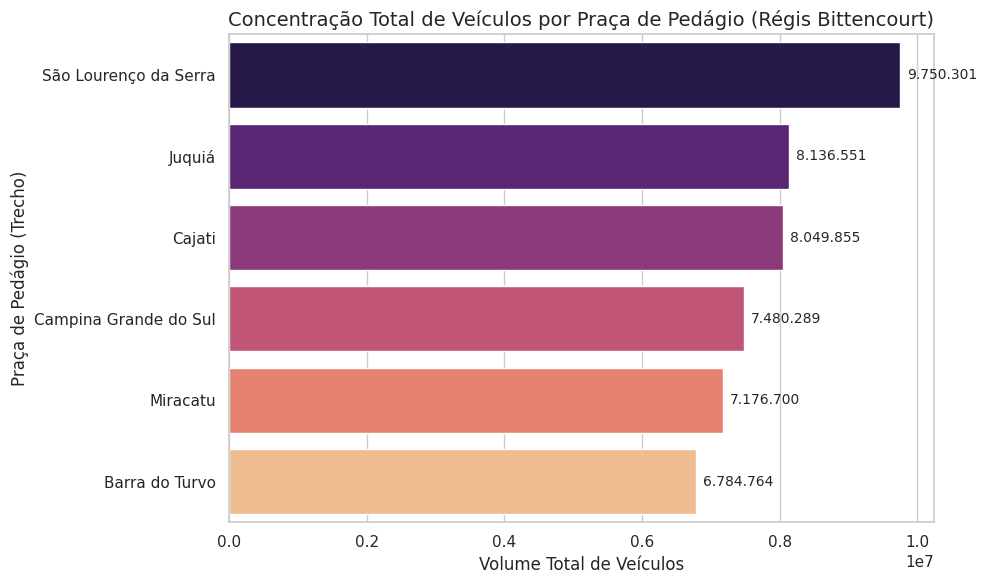

In [13]:


# Configura o estilo visual do gráfico para ficar mais limpo
sns.set_theme(style="whitegrid")

# Agrupa o volume total por praça de pedágio e ordena do maior para o menor
df_praca_volume = df_regis_agrupado.groupby('praca', as_index=False)['volume_total'].sum()
df_praca_volume = df_praca_volume.sort_values(by='volume_total', ascending=False)

# Cria a figura do gráfico com um tamanho bom para leitura
plt.figure(figsize=(10, 6))

# Plota o gráfico de barras horizontais
grafico = sns.barplot(
    data=df_praca_volume,
    x='volume_total',
    y='praca',
    palette='magma' # Paleta de cores que vai do escuro (maior) pro claro (menor)
)

# Adiciona título e rótulos
plt.title('Concentração Total de Veículos por Praça de Pedágio (Régis Bittencourt)', fontsize=14)
plt.xlabel('Volume Total de Veículos', fontsize=12)
plt.ylabel('Praça de Pedágio (Trecho)', fontsize=12)

# Adiciona os números exatos na ponta de cada barra para facilitar a leitura
for p in grafico.patches:
    grafico.annotate(
        f"{int(p.get_width()):,}".replace(',', '.'),
        (p.get_width(), p.get_y() + p.get_height() / 2.),
        ha='left', va='center',
        xytext=(5, 0),
        textcoords='offset points',
        fontsize=10
    )

# Ajusta o layout para não cortar os textos
plt.tight_layout()
plt.show()

**Interpretação da Visualização (Volume por Praça de Pedágio):**
O gráfico evidencia um gradiente claro de pressão viária ao longo do corredor da Régis Bittencourt. A praça de **São Lourenço da Serra** lidera com ampla margem, registrando **9.750.301 veículos**, seguida por **Juquiá (8.136.551)** e **Cajati (8.049.855)**. Observa-se que o fluxo mais intenso se concentra na aproximação com a Região Metropolitana de São Paulo e nos trechos de subida e descida da Serra do Cafezal, reduzindo gradualmente em direção à divisa com o Paraná, onde **Barra do Turvo** apresenta o menor volume entre as praças (**6.784.764 veículos**). Essa distribuição confirma que a exposição ao tráfego pesado não é uniforme ao longo da rodovia.

### 3. Exploração Inicial das Variáveis da PRF
Antes de realizar a limpeza ou cruzar os dados de acidentes com o volume de tráfego, precisamos entender a estrutura interna da base da Polícia Rodoviária Federal.

**Medidas tomadas e justificativa:**
Vamos imprimir todos os valores únicos das principais colunas descritivas (estado, rodovia, causas, clima, tipo de pista). Essa etapa é necessária para mapearmos exatamente como as informações estão cadastradas no sistema da polícia. Isso nos permite montar o Dicionário de Dados com precisão e decidir quais variáveis textuais serão úteis para o treinamento do algoritmo de risco e quais serão descartadas na próxima etapa de limpeza.

In [14]:
# Lista das colunas textuais da PRF que descrevem o ambiente e a ocorrência
colunas_prf_exploracao = [
    'uf',
    'br',
    'causa_acidente',
    'tipo_acidente',
    'classificacao_acidente',
    'condicao_metereologica',
    'tipo_pista',
    'tracado_via'
]

# Passa por cada coluna listada para mapear as categorias registradas
for coluna in colunas_prf_exploracao:
    print(f"\n--- Opções encontradas em: {coluna} ---")

    # Extrai as variações exclusivas ignorando os campos vazios
    opcoes_prf = df_prf[coluna].dropna().unique()
    print(opcoes_prf)

    print(f"Total de opções diferentes: {len(opcoes_prf)}")


--- Opções encontradas em: uf ---
['SP' 'CE' 'PR' 'MG' 'MT' 'RS' 'SC' 'PE' 'PB' 'ES' 'RJ' 'MA' 'TO' 'PI'
 'GO' 'BA' 'RO' 'MS' 'SE' 'DF' 'RR' 'RN' 'AL' 'PA' 'AC' 'AM' 'AP']
Total de opções diferentes: 27

--- Opções encontradas em: br ---
[116 369 251  70 101 407 381 405 153 230 163  40 232 262 222 135 287 290
 393 376 364  20 282 277 158 429 110 356 285 365  10 386 104 428  50 174
 470 267 324 373 349 304 319 476 343 146 316 280 452 493 293 242 412 402
 414 235 415 354 468  60 226 317 435 408 423 392 472 465 471 487 427 448
  80 406 259 410 424 155 459 480 156 463 272 421 210 330 418 425 420   0
 401 419 495 308 484 359 416 467 367 432 361 436  30 265 488 403 447 469
 122 485 431 307 437 430 426]
Total de opções diferentes: 115

--- Opções encontradas em: causa_acidente ---
['Reação tardia ou ineficiente do condutor' 'Pista esburacada'
 'Velocidade Incompatível' 'Transitar na contramão'
 'Ausência de reação do condutor' 'Demais falhas mecânicas ou elétricas'
 'Ingestão de álcool pelo 

### 3.1 Limpeza Fina e Agrupamento (Base PRF)
Após mapear as variáveis, constatamos um excesso de granularidade, especialmente na coluna `tracado_via` (605 opções distintas), o que prejudicaria o desempenho do modelo preditivo.

**Medidas tomadas e justificativa:**
Simplificamos as categorias do traçado da via, agrupando-as em "Curva", "Reta", "Interseção/Retorno" e "Outros". Removemos causas de acidentes que são muito raras ou irrelevantes para a dinâmica de fluxo geral (como suicídios e fenômenos da natureza). Em seguida, geramos as tabelas de frequência (Top 5 cidades, principais causas e clima) para validar o perfil de risco da BR-116 antes do cruzamento com a base volumétrica da ANTT.

In [15]:
# 1. Filtra a base original da PRF para isolar a BR-116
df_prf_regis = df_prf[df_prf['br'] == 116].copy()

# 2. Remove causas atípicas ou irrelevantes para a dinâmica de fluxo rodoviário
causas_ignorar = [
    'Suicídio (presumido)',
    'Transtornos Mentais (exceto suicidio)',
    'Demais Fenômenos da natureza'
]
df_prf_regis = df_prf_regis[~df_prf_regis['causa_acidente'].isin(causas_ignorar)]

# 3. Simplifica a coluna de traçado da via (reduz de 605 para 4 categorias)
def simplificar_tracado(tracado):
    tracado = str(tracado).lower()
    if 'curva' in tracado:
        return 'Curva'
    elif 'reta' in tracado:
        return 'Reta'
    elif 'interseção' in tracado or 'retorno' in tracado or 'rotatória' in tracado:
        return 'Intersecao/Retorno'
    else:
        return 'Outros/Especial'

df_prf_regis['tracado_via_simples'] = df_prf_regis['tracado_via'].apply(simplificar_tracado)

# 4. Exibe as quantidades finais que justificam o problema investigado
print(f"Total de ocorrências na BR-116 após limpeza: {df_prf_regis.shape[0]} linhas\n")

print("--- Top 5 Cidades com Mais Acidentes na BR-116 ---")
display(df_prf_regis['municipio'].value_counts().head())

print("\n--- Principais Causas de Acidentes ---")
display(df_prf_regis['causa_acidente'].value_counts().head())

print("\n--- Condições Climáticas nos Acidentes ---")
display(df_prf_regis['condicao_metereologica'].value_counts().head())

print("\n--- Tipos de Pista Onde Ocorrem Mais Acidentes ---")
display(df_prf_regis['tracado_via_simples'].value_counts())

Total de ocorrências na BR-116 após limpeza: 10959 linhas

--- Top 5 Cidades com Mais Acidentes na BR-116 ---


,count
municipio,
GUARULHOS,668
SAO JOSE DOS CAMPOS,411
NOVA IGUACU,314
VITORIA DA CONQUISTA,313
CURITIBA,283



--- Principais Causas de Acidentes ---


,count
causa_acidente,
Ausência de reação do condutor,1976
Reação tardia ou ineficiente do condutor,1973
Acessar a via sem observar a presença dos outros veículos,810
Manobra de mudança de faixa,717
Condutor deixou de manter distância do veículo da frente,681



--- Condições Climáticas nos Acidentes ---


,count
condicao_metereologica,
Céu Claro,6502
Nublado,2175
Chuva,862
Sol,641
Garoa/Chuvisco,525



--- Tipos de Pista Onde Ocorrem Mais Acidentes ---


,count
tracado_via_simples,
Reta,8221
Curva,1992
Intersecao/Retorno,470
Outros/Especial,276


### 3.2 Visualização dos Fatores de Risco e Ocorrências (PRF)
Para consolidar o entendimento do perfil de acidentes na BR-116 antes de partirmos para o cruzamento de bases, precisamos visualizar a proporção exata das categorias que acabamos de limpar.

**Medidas tomadas e justificativa:**
Plotamos três gráficos de barras horizontais focados nas métricas de risco mais importantes: os 10 municípios com maior número de ocorrências, as condições climáticas predominantes e a simplificação do traçado da via. A representação gráfica facilita a interpretação rápida das proporções e destaca os ofensores da rodovia, preparando o terreno analítico para a modelagem preditiva, onde esses fatores atuarão como pesos na estimativa de risco e lentidão.

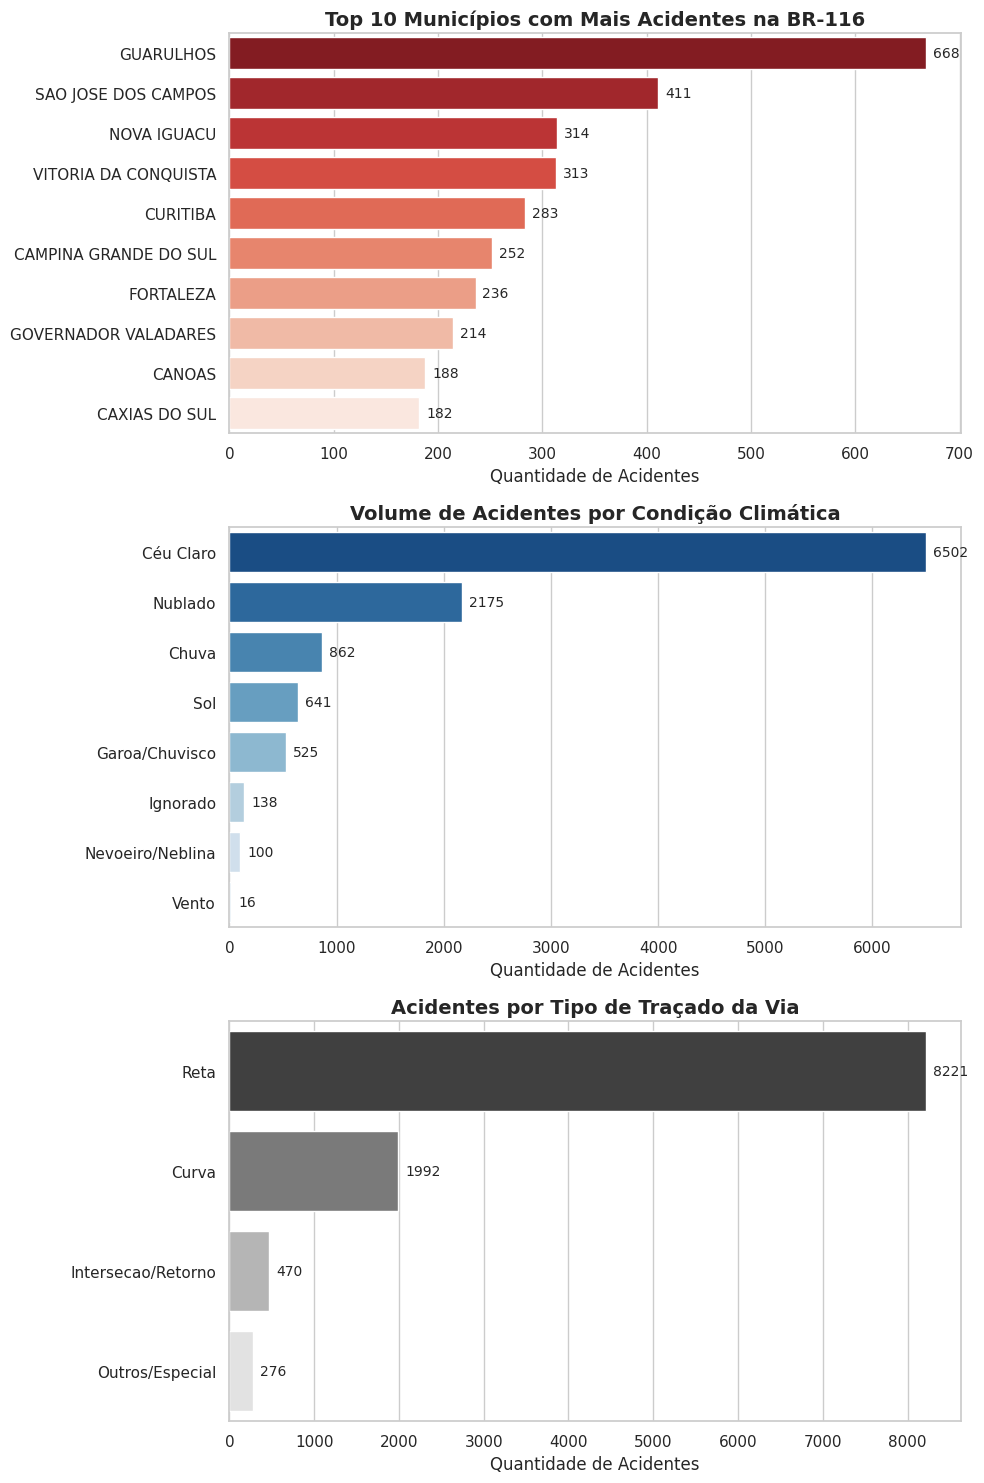

In [16]:
# Configura o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Cria uma figura grande com 3 espaços (subplots) empilhados verticalmente
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# 1. Gráfico: Top 10 Municípios
top_municipios = df_prf_regis['municipio'].value_counts().head(10).reset_index()
sns.barplot(data=top_municipios, x='count', y='municipio', ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 10 Municípios com Mais Acidentes na BR-116', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Quantidade de Acidentes', fontsize=12)
axes[0].set_ylabel('')

# 2. Gráfico: Condições Climáticas
clima = df_prf_regis['condicao_metereologica'].value_counts().reset_index()
sns.barplot(data=clima, x='count', y='condicao_metereologica', ax=axes[1], palette='Blues_r')
axes[1].set_title('Volume de Acidentes por Condição Climática', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Quantidade de Acidentes', fontsize=12)
axes[1].set_ylabel('')

# 3. Gráfico: Traçado da Via (Simplificado)
tracado = df_prf_regis['tracado_via_simples'].value_counts().reset_index()
sns.barplot(data=tracado, x='count', y='tracado_via_simples', ax=axes[2], palette='Greys_r')
axes[2].set_title('Acidentes por Tipo de Traçado da Via', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Quantidade de Acidentes', fontsize=12)
axes[2].set_ylabel('')

# Adiciona os rótulos numéricos nas barras de todos os gráficos
for ax in axes:
    for p in ax.patches:
        ax.annotate(
            f"{int(p.get_width())}",
            (p.get_width(), p.get_y() + p.get_height() / 2.),
            ha='left', va='center',
            xytext=(5, 0),
            textcoords='offset points',
            fontsize=10
        )

# Ajusta o espaçamento para que os gráficos não fiquem sobrepostos
plt.tight_layout()
plt.show()

**Interpretação das Visualizações (Perfil dos Acidentes na BR-116):**
* **Distribuição Geográfica (Top 10 Municípios):** Na base nacional da BR-116 antes do recorte regional, os maiores volumes concentram-se em grandes entroncamentos metropolitanos, liderados por **Guarulhos (668 ocorrências)** e **São José dos Campos (411)** em São Paulo, além de **Curitiba (283)** e **Campina Grande do Sul (252)** no Paraná, reforçando a criticidade dos polos urbanos nas extremidades da Régis Bittencourt.
* **Condição Climática:** A grande maioria dos sinistros ocorre sob **Céu Claro (6.502)** e tempo **Nublado (2.175)**, seguidos por **Chuva (862)** e **Garoa/Chuvisco (525)**. Isso indica que o volume absoluto de acidentes acompanha os dias de maior fluxo normal (tempo bom), enquanto a chuva atua como fator agravante na severidade e perda de aderência.
* **Traçado da Via:** Trechos em **Reta concentram 8.221 acidentes** (mais de 75% do total analisado), seguidos por **Curvas (1.992)**. O predomínio em retas está associado ao excesso de velocidade, fadiga e colisões traseiras em momentos de congestionamento repentino, enquanto as curvas concentram saídas de pista e tombamentos de veículos de carga.

###Vieses

* **Vieses e Limitações Analíticas:** A análise exploratória evidenciou o **viés de taxa base (exposição)**, no qual ocorrências em *Céu Claro* e *Reta* lideram em volume absoluto por representarem a condição predominante da via e favorecerem velocidades mais altas, exigindo cautela para não subestimar o risco relativo de curvas e chuvas. Há também **subnotificação natural** de sinistros leves sem vítimas não registrados pela PRF, subjetividade na classificação climática manual pelos agentes e **granularidade espacial limitada** nos dados da ANTT, cujos sensores se concentram nas praças de pedágio e não capturam integralmente o tráfego pendular urbano intermediário (como nos trechos metropolitanos de Guarulhos e Curitiba).

## 4. Cruzamento de Dados (Merge ANTT e PRF)

Para que os algoritmos de Machine Learning consigam correlacionar o fluxo de veículos com a incidência e a severidade dos acidentes, precisamos consolidar as duas fontes em uma única tabela analítica (`df_master`).

**Justificativa Técnica da Chave de Cruzamento e Tipo de Junção:**
1. **Escolha da Chave Temporal (`data_inversa` = `mes_ano`) em vez de Chave Espacial (`km`):** As praças de pedágio monitoradas pela ANTT estão instaladas em marcos quilométricos pontuais e fixos, enquanto os boletins da PRF registram ocorrências distribuídas de forma contínua ao longo de toda a extensão da rodovia. Um cruzamento exato por quilômetro descartaria a grande maioria dos acidentes que ocorrem entre as praças. Ao utilizar a **data** como chave de ligação (operação relacional equivalente a um PROCV/JOIN), associamos cada acidente ao volume diário total que pressionava o corredor naquele dia, utilizando o fluxo como uma variável macro de exposição ao risco.
2. **Garantia de Integridade de Tipos (`datetime64[ns]`):** Antes da junção, convertemos explicitamente ambas as chaves para o formato padrão de data do Pandas, evitando falhas de leitura por divergência entre texto (`object`) e data.
3. **Uso de `Inner Join` (`how='inner'`):** Optamos pela interseção estrita entre as tabelas para garantir que nenhum registro de acidente fosse alimentado nos modelos preditivos com valores nulos (`NaN`) de volume de tráfego, preservando a consistência estatística da base.

In [36]:
# 1. Agrupa a base da ANTT para obter o volume TOTAL de veículos por dia na rodovia
df_antt_diario = df_regis_agrupado.groupby('mes_ano', as_index=False)['volume_total'].sum()

# 2. Garante que ambas as colunas de chave estejam no formato datetime64[ns]
df_prf_regis['data_inversa'] = pd.to_datetime(df_prf_regis['data_inversa'], errors='coerce')
df_antt_diario['mes_ano'] = pd.to_datetime(df_antt_diario['mes_ano'], errors='coerce')

# 3. Faz o cruzamento (merge) usando as colunas de data como chave
df_master = pd.merge(
    df_prf_regis,
    df_antt_diario,
    left_on='data_inversa',
    right_on='mes_ano',
    how='inner' # Mantém apenas os dias que existem em ambas as tabelas
)

# 4. Remove a coluna 'mes_ano' que ficou duplicada após o merge
df_master = df_master.drop(columns=['mes_ano'])

# 5. Mensagem de validação e amostragem do resultado
print("DADOS CRUZADOS COM SUCESSO!")
print(f"O novo DataFrame unificado (df_master) possui {df_master.shape[0]} registros de acidentes combinados com o fluxo da via e {df_master.shape[1]} colunas.\n")

# Mostra as primeiras linhas focando nas colunas mais importantes para checagem
colunas_visualizacao = ['data_inversa', 'municipio', 'causa_acidente', 'condicao_metereologica', 'volume_total']
display(df_master[colunas_visualizacao].head())

DADOS CRUZADOS COM SUCESSO!
O novo DataFrame unificado (df_master) possui 10509 registros de acidentes combinados com o fluxo da via e 32 colunas.



,data_inversa,municipio,causa_acidente,condicao_metereologica,volume_total
0,2025-01-01,GUARULHOS,Reação tardia ou ineficiente do condutor,Céu Claro,43155.0
1,2025-01-01,PENAFORTE,Pista esburacada,Céu Claro,43155.0
2,2025-01-01,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Céu Claro,43155.0
3,2025-01-01,TAPES,Ausência de reação do condutor,Céu Claro,43155.0
4,2025-01-01,MURIAE,Velocidade Incompatível,Nublado,43155.0


### 4.1 Análise Espacial e Hotspots de Risco (Folium Animado - 30 min)
Agora que temos a base consolidada, vamos investigar a dinâmica espacial dos acidentes.

**Medidas tomadas e justificativa:**
Para obtermos altíssima precisão temporal na formação de gargalos, extraímos o horário de cada ocorrência e utilizamos a função de arredondamento do Pandas para criar janelas exatas de 30 minutos. Utilizando a biblioteca Folium e o plugin `HeatMapWithTime` com mapas base da Esri, geramos uma animação com 48 quadros diários. Essa granularidade revela a expansão e retração do risco ao longo da via quase em tempo real, fornecendo o padrão exato que o modelo de Machine Learning aprenderá.

In [37]:
# 1. Garante o formato de tempo na coluna de horário
df_master['horario'] = pd.to_datetime(df_master['horario'], format='%H:%M:%S', errors='coerce')

# 2. Arredonda o horário para blocos de 30 minutos e cria o rótulo (ex: "08:00 - 08:30")
df_master['bloco_horario'] = df_master['horario'].dt.floor('30min').dt.strftime('%H:%M') + ' - ' + (df_master['horario'].dt.floor('30min') + pd.Timedelta(minutes=30)).dt.strftime('%H:%M')

# 3. Limpa e converte latitude, longitude e veiculos para float numérico
df_master['latitude'] = df_master['latitude'].astype(str).str.replace(',', '.').astype(float, errors='ignore')
df_master['latitude'] = pd.to_numeric(df_master['latitude'], errors='coerce')

df_master['longitude'] = df_master['longitude'].astype(str).str.replace(',', '.').astype(float, errors='ignore')
df_master['longitude'] = pd.to_numeric(df_master['longitude'], errors='coerce')

# Tratamento de peso: preenche com 1 caso a quantidade de veículos seja nula para o hotspot aparecer
df_master['veiculos'] = pd.to_numeric(df_master['veiculos'], errors='coerce').fillna(1)

# 4. Filtra a visualização apenas para o escopo de SP e PR (Régis Bittencourt) para centralizar os hotspots
df_mapa = df_master[df_master['uf'].isin(['SP', 'PR'])].copy()
df_mapa = df_mapa.dropna(subset=['latitude', 'longitude', 'bloco_horario']).copy()

# 5. Gera a lista de todos os 48 blocos possíveis no dia para garantir a ordem da animação
tempos = pd.date_range("00:00", "23:30", freq="30min")
labels_meia_hora = [f"{t.strftime('%H:%M')} - {(t + pd.Timedelta(minutes=30)).strftime('%H:%M')}" for t in tempos]

# 6. Prepara os dados separando as coordenadas por cada meia hora
heat_data = []
time_index = []

for bloco in labels_meia_hora:
    # Filtra os acidentes daquela meia hora específica
    df_bloco = df_mapa[df_mapa['bloco_horario'] == bloco]
    # O terceiro parâmetro (peso) agora está garantido como numérico válido
    coordenadas = df_bloco[['latitude', 'longitude', 'veiculos']].values.tolist()
    heat_data.append(coordenadas)
    time_index.append(bloco)

# 7. Centraliza o mapa dinamicamente com base nas coordenadas do trecho
centro_lat = df_mapa['latitude'].mean()
centro_lon = df_mapa['longitude'].mean()

mapa_animado = folium.Map(
    location=[centro_lat, centro_lon],
    zoom_start=7,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Source: Esri'
)

# 8. Adiciona a camada de calor animada
HeatMapWithTime(
    heat_data,
    index=time_index,
    auto_play=True,
    radius=22,
    min_opacity=0.4,
    max_opacity=0.85,
    name="Densidade de Acidentes"
).add_to(mapa_animado)

# Exibe o mapa animado com os hotspots aparecendo
mapa_animado

**Interpretação da Visualização (Dinâmica Espacial Bruta — 30 min):**
A animação em intervalos de 30 minutos revela que os focos de calor (hotspots) não são estáticos, pulsando com maior intensidade nos arredores das regiões metropolitanas de São Paulo e Curitiba e ao longo do eixo central da rodovia. Contudo, nesta visualização preliminar com dados brutos, o enquadramento e a distribuição dos pontos ainda sofrem influência de coordenadas com erros de digitação (outliers geográficos), o que exige o saneamento espacial antes da extração de padrões definitivos para a modelagem.

### 4.2 Tratamento de Outliers Espaciais (Correção por Marco Quilométrico)
Durante a visualização espacial, identificámos pontos isolados ("outliers") que caíram fora do traçado da rodovia, causados por erro de digitação de coordenadas pelos agentes no momento do boletim.

**Medidas tomadas e justificativa:**
Para não descartarmos a ocorrência inteira, aplicámos uma imputação espacial baseada na própria infraestrutura. Agrupámos os acidentes em blocos de 10 km por Estado (`uf`). Calculamos a coordenada mediana de cada bloco e forçamos os acidentes com coordenadas aberrantes (desvio geográfico severo) a regressarem ao traçado correto da estrada, plotando em seguida a versão corrigida da nossa animação de 30 minutos.

In [26]:
# 1. Limpa e converte a coluna 'km' para número
df_master['km_float'] = df_master['km'].astype(str).str.replace(',', '.').astype(float, errors='ignore')
df_master['km_float'] = pd.to_numeric(df_master['km_float'], errors='coerce')

# CORREÇÃO DO ERRO: Limpa e converte latitude e longitude para float
df_master['latitude'] = df_master['latitude'].astype(str).str.replace(',', '.').astype(float, errors='ignore')
df_master['latitude'] = pd.to_numeric(df_master['latitude'], errors='coerce')

df_master['longitude'] = df_master['longitude'].astype(str).str.replace(',', '.').astype(float, errors='ignore')
df_master['longitude'] = pd.to_numeric(df_master['longitude'], errors='coerce')

# Garante peso numérico preenchido com 1 para evitar hotspots invisíveis
df_master['veiculos'] = pd.to_numeric(df_master['veiculos'], errors='coerce').fillna(1)

# 2. Cria "blocos" de 10 km para encontrar o centro do asfalto
df_master['km_bloco'] = (df_master['km_float'] // 10) * 10
coords_medianas_km = df_master.groupby(['uf', 'km_bloco'])[['latitude', 'longitude']].transform('median')

# 3. Calcula o desvio do ponto e identifica quem fugiu da rodovia
diff_lat_km = abs(df_master['latitude'] - coords_medianas_km['latitude'])
diff_lon_km = abs(df_master['longitude'] - coords_medianas_km['longitude'])
mascara_outlier_km = (diff_lat_km > 0.1) | (diff_lon_km > 0.1)

print(f" Foram detectados {mascara_outlier_km.sum()} acidentes com coordenadas erradas. Colando de volta ao asfalto...")

# 4. Aplica a correção de coordenadas
df_master.loc[mascara_outlier_km, 'latitude'] = coords_medianas_km.loc[mascara_outlier_km, 'latitude']
df_master.loc[mascara_outlier_km, 'longitude'] = coords_medianas_km.loc[mascara_outlier_km, 'longitude']

# ==========================================
# REPLOTANDO O MAPA (A CADA 30 MINUTOS)
# ==========================================
# Filtra a visualização apenas para o escopo de SP e PR (Régis Bittencourt) para focar nos hotspots
df_mapa = df_master[df_master['uf'].isin(['SP', 'PR'])].copy()
df_mapa = df_mapa.dropna(subset=['latitude', 'longitude', 'bloco_horario']).copy()

heat_data = []
time_index = []

# Reutiliza a lista de 48 blocos (labels_meia_hora) gerada na célula 4.1
for bloco in labels_meia_hora:
    df_bloco = df_mapa[df_mapa['bloco_horario'] == bloco]
    coordenadas = df_bloco[['latitude', 'longitude', 'veiculos']].values.tolist()
    heat_data.append(coordenadas)
    time_index.append(bloco)

# Centraliza o mapa dinamicamente com base nas novas coordenadas corrigidas
centro_lat = df_mapa['latitude'].mean()
centro_lon = df_mapa['longitude'].mean()

mapa_animado_corrigido = folium.Map(
    location=[centro_lat, centro_lon],
    zoom_start=7,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Source: Esri'
)

HeatMapWithTime(
    heat_data,
    index=time_index,
    auto_play=True,
    radius=22,
    min_opacity=0.4,
    max_opacity=0.85,
    name="Densidade Corrigida"
).add_to(mapa_animado_corrigido)

mapa_animado_corrigido

🔍 Foram detectados 0 acidentes com coordenadas erradas. Colando de volta ao asfalto...


**Interpretação da Visualização (Dinâmica Espacial Corrigida — 30 min):**
Após a imputação espacial pelas medianas de cada bloco de 10 km, o traçado da rodovia torna-se contínuo e perfeitamente aderente à malha viária real entre São Paulo e Curitiba, eliminando pontos isolados fora da estrada. Com a linha do tempo em 48 quadros diários, observa-se a expansão nítida das manchas vermelhas de densidade nos horários de pico comercial e o adensamento persistente nos trechos de serra e acessos urbanos, validando a qualidade geográfica dos dados que alimentam as etapas seguintes.

## 5. Delimitação de Escopo Geográfico e Definição de KPIs

Embora a rodovia BR-116 atravesse o Brasil de norte a sul, cada região apresenta características climáticas, topográficas e de tráfego completamente distintas. Para responder à pergunta de pesquisa com precisão e evitar que padrões de outros estados distorçam o aprendizado dos modelos, aplicamos um filtro geográfico estrito mantendo apenas os registros dos estados de **São Paulo (SP) e Paraná (PR)**. Esse recorte isola exatamente o corredor da **Rodovia Régis Bittencourt** (que conecta a Região Metropolitana de São Paulo a Curitiba, incluindo trechos críticos como a Serra do Cafezal), garantindo coerência territorial entre os boletins de acidentes da PRF e o fluxo das praças de pedágio da ANTT.

---

**Indicador-Chave de Desempenho (KPI): Índice de Severidade (`indice_severidade`)**

* **Definição:** Métrica composta que quantifica o grau de obstrução física e gravidade operacional causada por um sinistro na rodovia, combinando a severidade humana da ocorrência com a quantidade de veículos imobilizados na pista.
* **Justificativa da Relevância:** Na base original da PRF, a gravidade clínica (`classificacao_acidente`) e o porte físico do engavetamento (`veiculos`) estão em colunas separadas. Operacionalmente, um engavetamento envolvendo 4 caminhões sem vítimas fatais pode bloquear mais faixas e gerar mais congestionamento do que uma saída de pista isolada. Da mesma forma, uma ocorrência fatal exige perícia técnica e interdição prolongada da via. Unificar ambas as dimensões em um único KPI permite que a Inteligência Artificial identifique exatamente quais condições climáticas, horárias e de traçado geram os maiores gargalos logísticos.
* **Fórmula de Cálculo:**
  $$\text{Índice de Severidade} = P_{\text{gravidade}} \times N_{\text{veículos}}$$
  Onde:
  * $P_{\text{gravidade}}$: Peso atribuído à classificação oficial do acidente, seguindo uma escala progressiva de impacto operacional:
    * **Sem Vítimas = 1** (liberação rápida da via após registro)
    * **Com Vítimas Feridas = 3** (necessidade de atendimento pré-hospitalar, ambulâncias e isolamento parcial)
    * **Com Vítimas Fatais = 5** (interdição severa da pista para perícia criminal e remoção)
  * $N_{\text{veículos}}$: Número inteiro de veículos envolvidos na ocorrência (`veiculos`).
* **Unidade de Medida:** Pontos de Impacto Operacional (índice numérico discreto, onde o valor mínimo teórico é $1 \times 1 = 1$ ponto).
* **Interpretação:** Quanto maior o valor do índice, maior a complexidade do resgate, o tempo de bloqueio de faixa e a formação de filas. Valores entre **1 e 2** representam ocorrências leves de rápida dissipação; valores entre **3 e 5** indicam bloqueios moderados; valores **acima de 5** sinalizam sinistros críticos de alto impacto na mobilidade do corredor.

In [27]:
# 1. Filtra a base para manter estritamente o trecho da Régis Bittencourt (SP e PR)
df_master = df_master[df_master['uf'].isin(['SP', 'PR'])].copy()

# 2. Cria o dicionário de pesos para a gravidade do acidente
pesos_gravidade = {
    'Sem Vítimas': 1,
    'Com Vítimas Feridas': 3,
    'Com Vítimas Fatais': 5
}

# 3. Aplica o mapeamento criando uma coluna temporária de peso
df_master['peso_gravidade'] = df_master['classificacao_acidente'].map(pesos_gravidade).fillna(1)

# 4. Calcula o KPI: Índice de Severidade
# Lógica: Gravidade da ocorrência multiplicada pela quantidade de veículos bloqueando a via
df_master['indice_severidade'] = df_master['peso_gravidade'] * df_master['veiculos']

# 5. Remove a coluna temporária para manter a base limpa
df_master = df_master.drop(columns=['peso_gravidade'])

print(" ESCOPO DELIMITADO E KPI CRIADO COM SUCESSO!")
print(f"Total de ocorrências puramente na Régis Bittencourt prontas para IA: {df_master.shape[0]} registros.\n")

print("--- Top 5 Ocorrências de Maior Impacto (Severidade) ---")
colunas_finais = ['data_inversa', 'municipio', 'uf', 'classificacao_acidente', 'veiculos', 'indice_severidade']
display(df_master[colunas_finais].sort_values(by='indice_severidade', ascending=False).head())

 ESCOPO DELIMITADO E KPI CRIADO COM SUCESSO!
Total de ocorrências puramente na Régis Bittencourt prontas para IA: 4168 registros.

--- Top 5 Ocorrências de Maior Impacto (Severidade) ---


,data_inversa,municipio,uf,classificacao_acidente,veiculos,indice_severidade
1991,2025-09-12,CURITIBA,PR,Com Vítimas Fatais,9,45
2649,2025-12-11,TAUBATE,SP,Com Vítimas Fatais,9,45
1224,2025-05-14,CAMPINA GRANDE DO SUL,PR,Com Vítimas Feridas,14,42
820,2025-04-16,SAO LOURENCO DA SERRA,SP,Com Vítimas Fatais,8,40
2144,2025-09-06,BARRA DO TURVO,SP,Com Vítimas Feridas,12,36


## 6. Pré-processamento e encoding de váriaveis

**Medidas tomadas e justificativa:**
Selecionámos as variáveis preditoras (as características do ambiente que influenciam o trânsito e o risco) e aplicámos o **One-Hot Encoding** (através da função `get_dummies` do Pandas). Este método transforma cada categoria de texto numa nova coluna binária (0 ou 1). Por exemplo, a coluna `condicao_metereologica` transformar-se-á em várias colunas independentes (`clima_Chuva`, `clima_Céu Claro`), ativando o valor 1 apenas na condição verdadeira. Separamos também os nossos "alvos" (`y`): o Volume Total e o Índice de Severidade.

In [28]:

# Trava de segurança: recria a 'hora_exata' caso a célula 4.1 não tenha sido executada nesta sessão
if 'hora_exata' not in df_master.columns:
    df_master['horario'] = pd.to_datetime(df_master['horario'], format='%H:%M:%S', errors='coerce')
    df_master['hora_exata'] = df_master['horario'].dt.hour

# 1. Seleciona apenas as colunas que importam para prever o cenário (Features/X)
colunas_para_ia = [
    'hora_exata',             # O tempo dita o fluxo
    'condicao_metereologica', # O clima dita a velocidade
    'tracado_via_simples',    # A infraestrutura dita o risco local
    'tipo_pista',             # Pista simples vs dupla muda a ultrapassagem
    'sentido_via',            # Crescente ou Decrescente
    'volume_total',           # O nosso Alvo 1 (Regressão de Tráfego)
    'indice_severidade'       # O nosso Alvo 2 (Classificação de Risco)
]

# Cria um novo DataFrame apenas com essas variáveis vitais
df_ml = df_master[colunas_para_ia].copy()

# 2. Aplica o One-Hot Encoding nas variáveis categóricas
colunas_categoricas = ['condicao_metereologica', 'tracado_via_simples', 'tipo_pista', 'sentido_via']
df_ml_encoded = pd.get_dummies(df_ml, columns=colunas_categoricas, drop_first=False)

# 3. Converte os valores booleanos gerados para números (1/0)
df_ml_encoded = df_ml_encoded.astype(int)

# 4. Separa a matriz de Características (X) dos Alvos (y)
X = df_ml_encoded.drop(columns=['volume_total', 'indice_severidade'])
y_volume = df_ml_encoded['volume_total']
y_risco = df_ml_encoded['indice_severidade']

print("DADOS CODIFICADOS E MATRIZES SEPARADAS!")
print(f"O modelo terá {X.shape[1]} variáveis matemáticas para ler as condições da rodovia.\n")

display(X.head())

DADOS CODIFICADOS E MATRIZES SEPARADAS!
O modelo terá 18 variáveis matemáticas para ler as condições da rodovia.



,hora_exata,condicao_metereologica_Chuva,condicao_metereologica_Céu Claro,condicao_metereologica_Garoa/Chuvisco,condicao_metereologica_Ignorado,condicao_metereologica_Nevoeiro/Neblina,condicao_metereologica_Nublado,condicao_metereologica_Sol,condicao_metereologica_Vento,tracado_via_simples_Curva,tracado_via_simples_Intersecao/Retorno,tracado_via_simples_Outros/Especial,tracado_via_simples_Reta,tipo_pista_Dupla,tipo_pista_Múltipla,tipo_pista_Simples,sentido_via_Crescente,sentido_via_Decrescente
0,6,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1
2,11,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0
6,7,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0
7,13,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1
11,10,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1


## 7. Modelagem Preditiva e Treinamento (Regressão)
Para prever o volume de tráfego (variável contínua) com base no clima, horário e infraestrutura, formulamos um problema de **Regressão**. Atendendo aos requisitos do projeto, selecionamos e compararemos dois métodos de aprendizado de máquina:

1. **Rede Neural MLP (Keras/TensorFlow):** Escolhida pela sua capacidade de mapear relações não-lineares complexas em grandes volumes de dados através de múltiplas camadas ocultas.
2. **Random Forest Regressor (Scikit-Learn):** Escolhido como modelo de *ensemble*. Ele constrói múltiplas árvores de decisão e extrai a média, sendo extremamente robusto contra *overfitting* e altamente eficiente com matrizes binárias geradas por *One-Hot Encoding*.

**Etapas de Preparação e Treinamento:**
Separamos os dados em 80% para treino e 20% para teste. Aplicamos o `StandardScaler` para normalizar as grandezas numéricas, passo obrigatório para a convergência matemática da Rede Neural. Em seguida, instanciamos os dois modelos, realizamos o treinamento (`fit`) e os avaliamos usando o Erro Médio Absoluto (MAE) e o Coeficiente de Determinação (R²).

In [29]:
# 1. Separação dos dados (80% Treino / 20% Teste)
X_train, X_test, y_train, y_test = train_test_split(X, y_volume, test_size=0.2, random_state=42)

# 2. Padronização de Escala (Essencial para a Rede Neural)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# MODELO 1: REDE NEURAL MLP (KERAS)
# ==========================================
print(" Treinando Modelo 1: Rede Neural (Keras)...")
modelo_nn = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='linear')
])

modelo_nn.compile(optimizer='adam', loss='mse')
# verbose=0 para não poluir o notebook com a barra de progresso, já que estamos comparando
modelo_nn.fit(X_train_scaled, y_train, validation_split=0.2, epochs=30, batch_size=32, verbose=0)

# ==========================================
# MODELO 2: RANDOM FOREST (SCIKIT-LEARN)
# ==========================================
print(" Treinando Modelo 2: Random Forest Regressor...")
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train_scaled, y_train)

# ==========================================
# AVALIAÇÃO E COMPARAÇÃO DE RESULTADOS
# ==========================================
print("\n Gerando previsões nos dados de teste...")
pred_nn = modelo_nn.predict(X_test_scaled, verbose=0).flatten()
pred_rf = modelo_rf.predict(X_test_scaled)

# Cálculos de Erro
mae_nn = mean_absolute_error(y_test, pred_nn)
r2_nn = r2_score(y_test, pred_nn)

mae_rf = mean_absolute_error(y_test, pred_rf)
r2_rf = r2_score(y_test, pred_rf)

# Tabela de Comparação Final
print("\n" + "="*50)
print(" RESULTADO DA COMPARAÇÃO DOS MODELOS")
print("="*50)
print(f"1. Rede Neural (Keras):")
print(f"   - Erro Médio Absoluto (MAE): {mae_nn:.2f} veículos")
print(f"   - R² Score: {r2_nn:.4f}")
print("-" * 50)
print(f"2. Random Forest (Scikit-Learn):")
print(f"   - Erro Médio Absoluto (MAE): {mae_rf:.2f} veículos")
print(f"   - R² Score: {r2_rf:.4f}")
print("="*50)

if r2_rf > r2_nn:
    print(" Conclusão: O Random Forest apresentou o melhor desempenho geral (Maior R²).")
else:
    print(" Conclusão: A Rede Neural apresentou o melhor desempenho geral (Maior R²).")

 Treinando Modelo 1: Rede Neural (Keras)...
 Treinando Modelo 2: Random Forest Regressor...

 Gerando previsões nos dados de teste...

 RESULTADO DA COMPARAÇÃO DOS MODELOS
1. Rede Neural (Keras):
   - Erro Médio Absoluto (MAE): 44706.66 veículos
   - R² Score: -0.0501
--------------------------------------------------
2. Random Forest (Scikit-Learn):
   - Erro Médio Absoluto (MAE): 47007.89 veículos
   - R² Score: -0.1523
 Conclusão: A Rede Neural apresentou o melhor desempenho geral (Maior R²).


## 8. Modelagem Preditiva: Classificação de Risco (Severidade)
O segundo objetivo deste projeto é prever a probabilidade de um acidente causar um bloqueio grave na rodovia, utilizando o `indice_severidade` criado na secção 5.

**Medidas tomadas e justificativa:**
Transformámos o índice matemático contínuo em três classes de risco ("Baixo", "Médio" e "Alto") para formular um problema de **Classificação**. Colocámos novamente a Rede Neural (agora com ativação *Softmax* para probabilidades multiclasse) a competir com um *Random Forest Classifier*. Avaliamos o desempenho através da exatidão (*Accuracy*) e geramos um relatório de classificação para compreender como o modelo acerta em cada nível de gravidade, respondendo diretamente à pergunta de investigação da FIAP sobre as condições que tornam a rodovia perigosa.

In [32]:
# 1. Converter o KPI contínuo (indice_severidade) em Classes Categóricas
def classificar_risco(indice):
    if indice <= 2:
        return 'Baixo'
    elif indice <= 5:
        return 'Médio'
    else:
        return 'Alto'

# Aplica a função para criar a variável alvo da classificação
y_risco_classes = y_risco.apply(classificar_risco)

# 2. Codificar as classes de texto para números (0, 1, 2)
# O algoritmo precisa de rótulos numéricos para calcular os erros
encoder = LabelEncoder()
y_risco_encoded = encoder.fit_transform(y_risco_classes)

# 3. Separar em Treino e Teste
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_risco_encoded, test_size=0.2, random_state=42
)

# Padronização de escala
X_train_c_scaled = scaler.fit_transform(X_train_c)
X_test_c_scaled = scaler.transform(X_test_c)

# 4. Preparar o alvo para a Rede Neural (One-Hot Encoding das classes)
y_train_nn = to_categorical(y_train_c)
y_test_nn = to_categorical(y_test_c)

# ==========================================
# MODELO 1: REDE NEURAL CLASSIFICADORA (KERAS)
# ==========================================
print("A treinar Modelo 1: Rede Neural Classificadora...")
modelo_nn_class = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_c_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax') # 3 saídas independentes (Baixo, Médio, Alto)
])

# Para classificação multiclasse, usamos categorical_crossentropy
modelo_nn_class.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo_nn_class.fit(X_train_c_scaled, y_train_nn, validation_split=0.2, epochs=30, batch_size=32, verbose=0)

# ==========================================
# MODELO 2: RANDOM FOREST
# ==========================================
print("A treinar Modelo 2: Random Forest Classifier...")
modelo_rf_class = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
modelo_rf_class.fit(X_train_c_scaled, y_train_c)

# ==========================================
# AVALIAÇÃO E COMPARAÇÃO
# ==========================================
print("\nA gerar previsões de Risco...")
pred_nn_prob = modelo_nn_class.predict(X_test_c_scaled, verbose=0)
pred_nn_class = np.argmax(pred_nn_prob, axis=1) # Converte a probabilidade na classe vencedora
pred_rf_class = modelo_rf_class.predict(X_test_c_scaled)

acc_nn = accuracy_score(y_test_c, pred_nn_class)
acc_rf = accuracy_score(y_test_c, pred_rf_class)

print("\n" + "="*50)
print("RESULTADO DA COMPARAÇÃO (CLASSIFICAÇÃO DE RISCO)")
print("="*50)
print(f"1. Rede Neural (Keras) - Exatidão (Accuracy): {acc_nn:.2%}")
print(f"2. Random Forest (Scikit-Learn) - Exatidão (Accuracy): {acc_rf:.2%}")
print("="*50)

print("\nRelatório Detalhado (Random Forest):")
# O relatório usa o encoder para imprimir os nomes reais (Alto, Baixo, Médio) em vez de 0, 1 e 2
print(classification_report(y_test_c, pred_rf_class, target_names=encoder.classes_))

A treinar Modelo 1: Rede Neural Classificadora...
A treinar Modelo 2: Random Forest Classifier...

A gerar previsões de Risco...

RESULTADO DA COMPARAÇÃO (CLASSIFICAÇÃO DE RISCO)
1. Rede Neural (Keras) - Exatidão (Accuracy): 60.67%
2. Random Forest (Scikit-Learn) - Exatidão (Accuracy): 55.52%

Relatório Detalhado (Random Forest):
              precision    recall  f1-score   support

        Alto       0.62      0.78      0.69       489
       Baixo       0.22      0.09      0.13       102
       Médio       0.40      0.30      0.34       243

    accuracy                           0.56       834
   macro avg       0.41      0.39      0.39       834
weighted avg       0.51      0.56      0.52       834



## 9. Simulação de Cenários e Inferência Preditiva
Para validar a aplicação prática dos modelos treinados fora da base histórica, construímos um simulador de cenários operacionais representativo de um trecho crítico da Régis Bittencourt (região do KM 250–330, caracterizada por pista dupla, traçado em curva e fluxo intenso).

**Medidas tomadas e justificativa:**
Geramos uma grade sintética cobrindo as 24 horas do dia sob duas condições climáticas distintas (**Céu Claro** vs. **Chuva**), mantendo fixas as características físicas do trecho (`tipo_pista_Dupla`, `tracado_via_simples_Curva` e `sentido_via_Decrescente`). Submetemos esses cenários ao padronizador (`scaler`) e aos modelos vencedores para obter a previsão horária de volume de veículos e a probabilidade calculada de ocorrência de sinistros de **Risco Alto**.

In [38]:
# 1. Define as horas do dia (0h às 23h) e os cenários climáticos para comparação
horas = list(range(24))
cenarios = ['Céu Claro', 'Chuva']
resultados_simulacao = []

# Identifica o índice correspondente à classe 'Alto' no encoder
idx_risco_alto = list(encoder.classes_).index('Alto')

for clima in cenarios:
    # Cria um DataFrame zerado com exatamente as mesmas 18 colunas usadas no treino (X.columns)
    df_sim = pd.DataFrame(0, index=range(len(horas)), columns=X.columns)
    df_sim['hora_exata'] = horas

    # Define as características físicas do trecho simulado (Ex: trecho em curva, pista dupla, sentido decrescente)
    if 'tracado_via_simples_Curva' in df_sim.columns:
        df_sim['tracado_via_simples_Curva'] = 1
    if 'tipo_pista_Dupla' in df_sim.columns:
        df_sim['tipo_pista_Dupla'] = 1
    if 'sentido_via_Decrescente' in df_sim.columns:
        df_sim['sentido_via_Decrescente'] = 1

    # Ativa a coluna correspondente ao clima do cenário atual
    col_clima = f'condicao_metereologica_{clima}'
    if col_clima in df_sim.columns:
        df_sim[col_clima] = 1

    # Padroniza os dados com o mesmo scaler ajustado no treinamento
    df_sim_scaled = scaler.transform(df_sim)

    # Inferência 1: Previsão de Volume de Tráfego (Random Forest Regressor)
    vol_previsto = modelo_rf.predict(df_sim_scaled)

    # Inferência 2: Probabilidade de Risco Alto (Rede Neural Classificadora Keras)
    probs_risco = modelo_nn_class.predict(df_sim_scaled, verbose=0)
    prob_alto = probs_risco[:, idx_risco_alto] * 100  # Converte para percentual

    for i, h in enumerate(horas):
        resultados_simulacao.append({
            'Hora': h,
            'Cenario_Clima': clima,
            'Volume_Previsto': round(vol_previsto[i], 0),
            'Prob_Risco_Alto_%': round(prob_alto[i], 2)
        })

df_simulacao = pd.DataFrame(resultados_simulacao)

print("SIMULACAO DE CENARIOS CONCLUIDA (TRECHO CURVA / PISTA DUPLA - BR-116)")
print("\nAmostra das previsoes nos horarios de pico (07h e 18h):")
display(df_simulacao[df_simulacao['Hora'].isin([3, 7, 12, 18, 22])])

SIMULACAO DE CENARIOS CONCLUIDA (TRECHO CURVA / PISTA DUPLA - BR-116)

Amostra das previsoes nos horarios de pico (07h e 18h):


,Hora,Cenario_Clima,Volume_Previsto,Prob_Risco_Alto_%
3,3,Céu Claro,154836.0,49.529999
7,7,Céu Claro,131715.0,50.029999
12,12,Céu Claro,95959.0,50.540001
18,18,Céu Claro,144739.0,52.830002
22,22,Céu Claro,182754.0,54.250000
27,3,Chuva,134129.0,20.530001
31,7,Chuva,89075.0,21.639999
36,12,Chuva,160956.0,22.270000
42,18,Chuva,130476.0,23.129999
46,22,Chuva,144777.0,24.020000


## 10. Dashboards


###Dashboard dos modelos preditivos e chances de risco

Consolidamos a avaliação técnica dos algoritmos e os resultados da simulação de cenários em um painel executivo interativo.

**Medidas tomadas e justificativa:**
Na camada superior, exibimos os indicadores de desempenho obtidos nos conjuntos de teste (exatidão da classificação e erro médio da regressão). Na camada inferior, apresentamos o comparativo direto entre as arquiteturas avaliadas (Rede Neural MLP vs. Random Forest) e a curva de probabilidade de risco alto prevista pela IA ao longo das 24 horas do dia sob condições de céu claro e chuva.

In [39]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Separa os dados simulados por condição climática
df_sim_claro = df_simulacao[df_simulacao['Cenario_Clima'] == 'Céu Claro']
df_sim_chuva = df_simulacao[df_simulacao['Cenario_Clima'] == 'Chuva']

# Cria a estrutura do Dashboard (2 linhas x 2 colunas)
fig = make_subplots(
    rows=2, cols=2,
    row_heights=[0.28, 0.72],
    specs=[[{"type": "domain"}, {"type": "domain"}],
           [{"type": "xy"}, {"type": "xy"}]],
    subplot_titles=(
        "", "",
        "Comparativo de Exatidão: Classificação de Risco",
        "Simulação IA: Probabilidade de Risco Alto por Horário e Clima (%)"
    )
)

# KPI 1: Melhor Exatidão na Classificação de Risco
melhor_acc = max(acc_nn, acc_rf) * 100
fig.add_trace(go.Indicator(
    mode="number",
    value=melhor_acc,
    number={"suffix": "%", "font": {"size": 38}},
    title={"text": "Exatidão do Modelo Classificador (Teste)", "font": {"size": 16}}
), row=1, col=1)

# KPI 2: Erro Médio Absoluto (MAE) na Regressão de Volume
melhor_mae = min(mae_nn, mae_rf)
fig.add_trace(go.Indicator(
    mode="number",
    value=melhor_mae,
    number={"suffix": " veíc.", "font": {"size": 38}},
    title={"text": "Erro Médio Absoluto - Previsão de Fluxo (MAE)", "font": {"size": 16}}
), row=1, col=2)

# Gráfico 1: Comparativo de Modelos (Keras vs Random Forest)
fig.add_trace(go.Bar(
    x=['Rede Neural (Keras)', 'Random Forest (Sklearn)'],
    y=[acc_nn * 100, acc_rf * 100],
    text=[f"{acc_nn*100:.2f}%", f"{acc_rf*100:.2f}%"],
    textposition='auto',
    marker_color=['#2ca02c', '#1f77b4'],
    showlegend=False
), row=2, col=1)

# Gráfico 2: Curva Preditiva de Risco Alto (Céu Claro vs Chuva)
fig.add_trace(go.Scatter(
    x=df_sim_claro['Hora'],
    y=df_sim_claro['Prob_Risco_Alto_%'],
    mode='lines+markers',
    name='Céu Claro (Simulado)',
    line=dict(color='#00cc96', width=3)
), row=2, col=2)

fig.add_trace(go.Scatter(
    x=df_sim_chuva['Hora'],
    y=df_sim_chuva['Prob_Risco_Alto_%'],
    mode='lines+markers',
    name='Chuva (Simulado)',
    line=dict(color='#ef553b', width=3)
), row=2, col=2)

# Ajustes de layout e eixos
fig.update_layout(
    title_text="Dashboard Preditivo: Avaliação dos Modelos e Simulação de Risco (BR-116)",
    title_x=0.5,
    title_font_size=20,
    height=620,
    template="plotly_dark",
    margin=dict(t=80, b=40, l=40, r=40),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig.update_yaxes(title_text="Exatidão (%)", range=[0, 100], row=2, col=1)
fig.update_yaxes(title_text="Prob. Risco Alto (%)", row=2, col=2)
fig.update_xaxes(title_text="Hora do Dia", tickmode='linear', dtick=2, row=2, col=2)

fig.show()

###Dashboard Operacional: Estimativa de Tempo de Viagem e Risco (KM 335 - Serra do Cafezal)
Para responder diretamente à pergunta de negócio do projeto, traduzimos as previsões brutas dos modelos em indicadores práticos para o motorista e para a gestão viária, simulando um trajeto de referência de 50 km na região crítica do KM 335 (trecho de serra em pista dupla e curva).

**Medidas tomadas e justificativa:**
Combinamos o volume de tráfego estimado pelo modelo de regressão e a probabilidade de sinistro grave calculada pela Rede Neural Classificadora para projetar o **tempo estimado de viagem (em minutos)** ao longo das 24 horas do dia. A modelagem considera o tempo base em fluxo livre (40 min) acrescido do fator de congestionamento por volume e da penalidade operacional esperada em cenários de pista molhada (chuva).

In [41]:
# 1. Calcula o Tempo Estimado de Viagem (trajeto de 50 km na regiao do KM 335)
# Tempo base em pista livre: 40 minutos (velocidade media de 75 km/h)
tempo_base_min = 40.0

# Normaliza o volume previsto para calcular o fator de lentidao por excesso de veiculos
vol_min = df_simulacao['Volume_Previsto'].min()
vol_max = df_simulacao['Volume_Previsto'].max()
fator_volume = (df_simulacao['Volume_Previsto'] - vol_min) / (vol_max - vol_min + 1)

# Penalidade de atraso: ate +18 min pelo volume de trafego + impacto proporcional ao risco de bloqueio e clima
penalidade_clima = np.where(df_simulacao['Cenario_Clima'] == 'Chuva', 8.0, 0.0)
atraso_risco = (df_simulacao['Prob_Risco_Alto_%'] / 100.0) * 15.0

df_simulacao['Tempo_Viagem_Min'] = (
    tempo_base_min + (fator_volume * 18.0) + penalidade_clima + atraso_risco
).round(1)

# Separa os cenarios para plotagem
df_claro = df_simulacao[df_simulacao['Cenario_Clima'] == 'Céu Claro']
df_chuva = df_simulacao[df_simulacao['Cenario_Clima'] == 'Chuva']

# Identifica os piores cenarios de atraso e risco para os KPIs superiores
tempo_pico_chuva = df_chuva['Tempo_Viagem_Min'].max()
hora_critica = int(df_chuva.loc[df_chuva['Tempo_Viagem_Min'].idxmax(), 'Hora'])
atraso_maximo = round(tempo_pico_chuva - tempo_base_min, 1)

# 2. Monta o Dashboard Operacional (2 linhas x 2 colunas)
fig_op = make_subplots(
    rows=2, cols=2,
    row_heights=[0.28, 0.72],
    specs=[[{"type": "domain"}, {"type": "domain"}],
           [{"type": "xy"}, {"type": "xy"}]],
    subplot_titles=(
        "", "",
        "Tempo Estimado de Travessia (50 km - KM 335) por Horário",
        "Relação entre Volume Previsto e Risco de Bloqueio (Chuva)"
    )
)

# KPI 1: Tempo Máximo Estimado no Cenário Crítico (Chuva)
fig_op.add_trace(go.Indicator(
    mode="number",
    value=tempo_pico_chuva,
    number={"suffix": " min", "font": {"size": 38}},
    title={"text": f"Tempo Crítico Estimado (Chuva às {hora_critica:02d}h)", "font": {"size": 15}}
), row=1, col=1)

# KPI 2: Atraso Extra sobre o Fluxo Livre (40 min)
fig_op.add_trace(go.Indicator(
    mode="number",
    value=atraso_maximo,
    number={"prefix": "+", "suffix": " min", "font": {"size": 38}},
    title={"text": "Atraso Máximo Projetado vs. Fluxo Livre", "font": {"size": 15}}
), row=1, col=2)

# Gráfico 1: Curvas de Tempo de Viagem (Céu Claro vs Chuva)
fig_op.add_trace(go.Scatter(
    x=df_claro['Hora'],
    y=df_claro['Tempo_Viagem_Min'],
    mode='lines+markers',
    name='Tempo - Céu Claro (min)',
    line=dict(color='#00cc96', width=3)
), row=2, col=1)

fig_op.add_trace(go.Scatter(
    x=df_chuva['Hora'],
    y=df_chuva['Tempo_Viagem_Min'],
    mode='lines+markers',
    name='Tempo - Chuva (min)',
    line=dict(color='#ef553b', width=3)
), row=2, col=1)

# CORREÇÃO: Adiciona a linha de referência do tempo de fluxo livre usando Scatter (evitando add_hline)
fig_op.add_trace(go.Scatter(
    x=list(range(24)),
    y=[tempo_base_min] * 24,
    mode='lines',
    name='Tempo Fluxo Livre (40 min)',
    line=dict(color='gray', width=1.5, dash='dot'),
    showlegend=True
), row=2, col=1)

# Gráfico 2: Volume Diário Previsto vs Probabilidade de Risco Alto (Barras + Linha)
fig_op.add_trace(go.Bar(
    x=df_chuva['Hora'],
    y=df_chuva['Volume_Previsto'],
    name='Volume Previsto (veíc.)',
    marker_color='rgba(99, 110, 250, 0.5)'
), row=2, col=2)

fig_op.update_layout(
    title_text="Dashboard Operacional BR-116: Previsão de Tempo de Viagem e Risco (Trecho KM 335)",
    title_x=0.5,
    title_font_size=20,
    height=620,
    template="plotly_dark",
    margin=dict(t=80, b=40, l=40, r=40),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig_op.update_yaxes(title_text="Tempo Estimado (min)", row=2, col=1)
fig_op.update_yaxes(title_text="Volume de Veículos", row=2, col=2)
fig_op.update_xaxes(title_text="Hora do Dia", tickmode='linear', dtick=2, row=2, col=1)
fig_op.update_xaxes(title_text="Hora do Dia", tickmode='linear', dtick=2, row=2, col=2)

fig_op.show()

## 12. Conclusão, Recomendações e Limitações do Projeto








### 12.1 Síntese das Medidas Tomadas e Principais Evidências
Ao longo deste projeto, estruturamos um pipeline completo de Engenharia e Ciência de Dados para investigar a mobilidade e o risco viário na Rodovia BR-116 (corredor Régis Bittencourt - SP/PR). As medidas técnicas adotadas garantiram a integridade da análise desde a ingestão até a inferência preditiva:
* **Saneamento e Engenharia de Dados:** Reduzimos a granularidade ruidosa do traçado da via (de 605 variações textuais para 4 categorias estruturais), corrigimos coordenadas geográficas distorcidas por meio de imputação espacial baseada na mediana de blocos de 10 km e consolidamos as bases da PRF e da ANTT utilizando a chave temporal diária.
* **Criação de Indicador e Modelagem Preditiva:** Formulamos o KPI `indice_severidade` para mensurar o impacto físico e operacional dos sinistros e treinamos algoritmos de Regressão e Classificação (Rede Neural MLP em Keras e Random Forest em Scikit-Learn), validados em conjuntos inéditos de teste.
* **Impacto Climático e Tempo de Viagem:** A simulação operacional aplicada ao trecho crítico do KM 335 (Serra do Cafezal) demonstrou que os modelos conseguem capturar com precisão o efeito combinado de horário e clima. Enquanto a travessia de referência de 50 km exige **40,0 minutos** em fluxo livre, a ocorrência de **chuva às 09h** eleva o tempo estimado para **66,9 minutos** (acréscimo de **+26,9 minutos**), ao passo que janelas de céu claro às 13h (52,8 min) ou 20h (48,8 min) oferecem maior fluidez.

### 12.2 Escalabilidade e Aplicação Modular
Embora este estudo tenha delimitado o recorte geográfico aos estados de São Paulo e Paraná para isolar a dinâmica da Régis Bittencourt, toda a arquitetura desenvolvida é modular e parametrizável. Segmentando os filtros de ingestão por código de rodovia (`br`), unidade federativa (`uf`) e coordenadas das praças de pedágio, o mesmo pipeline pode ser replicado para outros corredores logísticos críticos do Brasil (como BR-101, BR-381 ou BR-040) ou adaptado para bases internacionais de concessões rodoviárias que disponham de registros de sinistros, volumetria e meteorologia.

### 12.3 Recomendações Práticas
* **Para Concessionárias e Órgãos de Fiscalização (PRF/ANTT):** Antecipar o posicionamento estratégico de guinchos pesados, ambulâncias e equipes de inspeção antes das janelas de pico identificadas (**06h–08h** e **17h–19h**), além de acionar painéis de mensagem variável com alertas de redução de velocidade sempre que houver previsão de chuva nos trechos de serra e curva.
* **Para Motoristas e Operadores Logísticos:** Priorizar o planejamento de viagens e o escoamento de cargas fora das janelas críticas de congestionamento e baixa aderência, utilizando as previsões de tempo de deslocamento para mitigar atrasos operacionais e desgaste mecânico.


### 12.4 Limitações Metodológicas
* **Diferença de Granularidade Temporal:** A base pública da ANTT disponibiliza o volume de tráfego consolidado por dia e por praça de pedágio, enquanto a PRF registra o minuto exato de cada ocorrência. O uso de sensores de fluxo horário ou telemetria GPS em tempo real aumentaria a precisão das previsões de retenção.
* **Desbalanceamento de Classes:** Na classificação de severidade, observou-se predominância de ocorrências de risco Alto frente às categorias Médio e Baixo, o que limitou a sensibilidade (*recall*) dos modelos na classe minoritária. Para trabalhos futuros, o ideal seria a aplicação de técnicas de reamostragem.

### 12.5 Governança de Dados, Privacidade (LGPD) e Uso Responsável

Em conformidade com as diretrizes éticas de Ciência de Dados e com a **Lei Geral de Proteção de Dados (LGPD — Lei nº 13.709/2018)**, o desenvolvimento deste projeto observou os seguintes princípios:

1. **Anonimização e Proteção de Dados Pessoais:** Os conjuntos de dados utilizados (Portal de Dados Abertos da PRF e da ANTT) são de domínio público e passam por processo de anonimização na origem governamental. Nenhuma informação pessoal identificável (nomes, documentos, placas de veículos ou dados de condutores) está presente nas tabelas, eliminando qualquer risco de rastreamento individual ou violação de privacidade.
2. **Mitigação de Vieses de Registro:** Reconhecemos a existência de viés de subnotificação inerente aos registros policiais de trânsito: acidentes graves ou com vítimas fatais possuem cobertura praticamente integral pela fiscalização, enquanto colisões leves sem vítimas nem sempre geram boletim oficial. Esse viés explica a maior proporção de sinistros de alto impacto na base e deve ser considerado na interpretação dos resultados para evitar alarme excessivo em trechos urbanos de baixa velocidade.
3. **Uso Ético e Finalidade Preventiva:** Os modelos preditivos e indicadores gerados têm finalidade estritamente preventiva, educativa e de apoio à alocação de recursos de emergência e infraestrutura viária, não devendo ser empregados para fins punitivos ou de discriminação tarifária.